# Telemanom data inspection

Goal: understand telemetry array structure and annotation alignment
before constructing features or training models.

In [1]:
from pathlib import Path

Path.cwd()

WindowsPath('c:/dev/satmon/satmon/notebooks')

In [2]:
import numpy as np

path = Path("../data/raw/archive/data/data/test/P-1.npy")
values = np.load(path, allow_pickle=False)

print("Shape:", values.shape)
print("Data Type:", values.dtype)
print("First five telemetry values:", values[:5, 0])

Shape: (8505, 25)
Data Type: float64
First five telemetry values: [-0.69516194 -0.68570386 -0.72571851 -0.76136787 -0.74536192]


In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
signal = values[:, 0]

print("Signal shape:", signal.shape)
print("All values finite:", np.isfinite(signal).all())
print("Minimum:", signal.min())
print("Maximum:", signal.max())

Signal shape: (8505,)
All values finite: True
Minimum: -1.0
Maximum: 1.0000000000000004


In [5]:
import pandas as pd

annotations = pd.read_csv("../data/raw/labeled_anomalies.csv")
p1_annotations = annotations.loc[annotations["chan_id"] == "P-1"]

p1_annotations

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505


In [6]:
from satmon.data import parse_intervals

intervals = parse_intervals(
    text=p1_annotations.iloc[0]["anomaly_sequences"],
    n_samples=len(signal),
)

print(intervals)
print(type(intervals))

[(2149, 2349), (4536, 4844), (3539, 3779)]
<class 'list'>


In [7]:
for start, end in intervals:
    if 0 <= start <= end < len(signal):
        print(f"({start}, {end})")
    else:
        print("failure")

(2149, 2349)
(4536, 4844)
(3539, 3779)


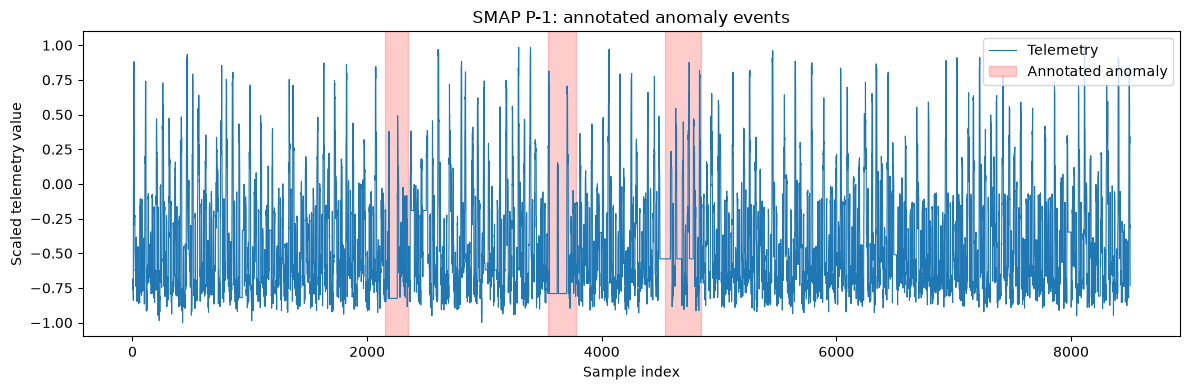

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(signal, linewidth=0.8, label="Telemetry")

for i, (start, end) in enumerate(sorted(intervals)):
    ax.axvspan(
        start,
        end,
        color="red",
        alpha=0.2,
        label="Annotated anomaly" if i == 0 else None,
    )

ax.set(
    xlabel="Sample index",
    ylabel="Scaled telemetry value",
    title="SMAP P-1: annotated anomaly events",
)
ax.legend()
fig.tight_layout()
plt.show()

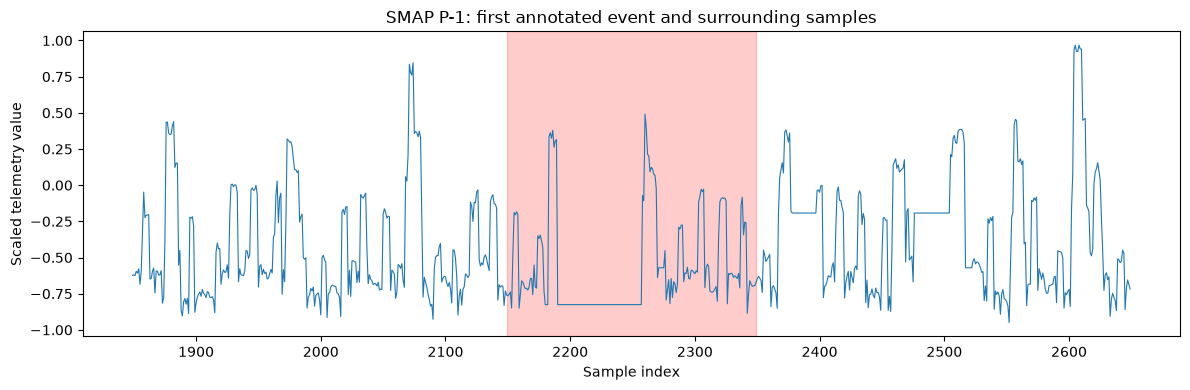

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))

start, end = sorted(intervals)[0]
left = max(0, start - 300)
right = min(len(signal), end + 301)

ax.plot(range(left, right), signal[left:right], linewidth=0.8)
ax.axvspan(start, end, color="red", alpha=0.2)

ax.set(
    xlabel="Sample index",
    ylabel="Scaled telemetry value",
    title="SMAP P-1: first annotated event and surrounding samples",
)
fig.tight_layout()
plt.show()

Within P-1’s first annotated event, a nearly constant segment appears around samples 2190–2260. Its magnitude is not unique to the event. This motivates investigating local variability alongside telemetry value; it does not establish the anomaly’s physical cause.

In [10]:
print("Annotation rows:", len(annotations))
print("Unique channel IDs:", annotations["chan_id"].nunique())

print("\nUnique channels by spacecraft:")
print(annotations.groupby("spacecraft")["chan_id"].nunique())

duplicate_rows = annotations.loc[
    annotations.duplicated("chan_id", keep=False)
]

print("\nRepeated channel IDs:")
display(duplicate_rows)

Annotation rows: 82
Unique channel IDs: 81

Unique channels by spacecraft:
spacecraft
MSL     27
SMAP    54
Name: chan_id, dtype: int64

Repeated channel IDs:


,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


In [11]:
raw_dir = Path("../data/raw")

for csv_path in raw_dir.rglob("labeled_anomalies.csv"):
    print(csv_path)

..\data\raw\labeled_anomalies.csv
..\data\raw\archive\labeled_anomalies.csv


In [12]:
archive_annotations = pd.read_csv(
    "../data/raw/archive/labeled_anomalies.csv"
)

print("Tables identical:", annotations.equals(archive_annotations))
print("Archive rows:", len(archive_annotations))
print("Archive unique channels:", archive_annotations["chan_id"].nunique())

display(
    archive_annotations.loc[
        archive_annotations["chan_id"] == "P-2"
    ]
)

Tables identical: True
Archive rows: 82
Archive unique channels: 81


,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


Both annotation copies are identical. P-2 has two overlapping but different annotated intervals for the same sequence. We exclude this channel from the primary experiment because its event definition is ambiguous, retaining the original annotations unchanged.

In [13]:
eligible_annotations = annotations.loc[
    annotations["chan_id"] != "P-2"
].copy()

assert eligible_annotations["chan_id"].is_unique

print("Eligible channels:", len(eligible_annotations))
print(eligible_annotations.groupby("spacecraft")["chan_id"].nunique())

Eligible channels: 80
spacecraft
MSL     27
SMAP    53
Name: chan_id, dtype: int64


In [14]:
test_dir = Path("../data/raw/archive/data/data/test")

missing_channels = []

for channel_id in eligible_annotations["chan_id"]:
    channel_path = test_dir / f"{channel_id}.npy"

    if not channel_path.is_file():
        missing_channels.append(channel_id)

print("Missing test files:", missing_channels)

Missing test files: []


In [15]:
from sklearn.model_selection import train_test_split

# P-1 is reserved for training because it informed feature exploration.
remaining = eligible_annotations.loc[
    eligible_annotations["chan_id"] != "P-1"
].copy()

train_pool, holdout = train_test_split(
    remaining,
    test_size=32,
    random_state=42,
    stratify=remaining["spacecraft"],
)

validation, test = train_test_split(
    holdout,
    test_size=16,
    random_state=42,
    stratify=holdout["spacecraft"],
)

train = pd.concat([
    train_pool,
    eligible_annotations.loc[eligible_annotations["chan_id"] == "P-1"],
])

for name, table in [
    ("train", train),
    ("validation", validation),
    ("test", test),
]:
    print(name, len(table))
    print(table.groupby("spacecraft").size())

train 48
spacecraft
MSL     16
SMAP    32
dtype: int64
validation 16
spacecraft
MSL      5
SMAP    11
dtype: int64
test 16
spacecraft
MSL      6
SMAP    10
dtype: int64


In [16]:
train_ids = set(train["chan_id"])
validation_ids = set(validation["chan_id"])
test_ids = set(test["chan_id"])

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)

assert train_ids | validation_ids | test_ids == set(
    eligible_annotations["chan_id"]
)

assert "P-1" in train_ids
assert "P-2" not in train_ids | validation_ids | test_ids

print("Split checks passed.")

Split checks passed.


In [17]:
import hashlib
import json

split_record = {
    "seed": 42,
    "annotation_sha256": hashlib.sha256(
        Path("../data/raw/labeled_anomalies.csv").read_bytes()
    ).hexdigest(),
    "excluded_channels": {
        "P-2": "Conflicting overlapping annotations in duplicate rows."
    },
    "reserved_training_channels": {
        "P-1": "Inspected before splitting and used to motivate features."
    },
    "train": sorted(train_ids),
    "validation": sorted(validation_ids),
    "test": sorted(test_ids),
}

split_path = Path("../splits/channels.json")
split_path.parent.mkdir(parents=True, exist_ok=True)

# Refuse to overwrite an existing split with different assignments.
if split_path.exists():
    saved_record = json.loads(split_path.read_text(encoding="utf-8"))
    assert saved_record == split_record, "Existing split differs; investigate."
else:
    split_path.write_text(
        json.dumps(split_record, indent=2) + "\n",
        encoding="utf-8",
    )

print("Saved and verified:", split_path.resolve())

Saved and verified: C:\dev\satmon\satmon\splits\channels.json


In [18]:
annotation_issues = []

for _, row in train.iterrows():
    events = parse_intervals(
        row["anomaly_sequences"],
        int(row["num_values"]),
    )

    event_types = [
        item.strip()
        for item in row["class"].strip("[]").split(",")
        if item.strip()
    ]

    if len(events) != len(event_types):
        annotation_issues.append(
            (row["chan_id"], "Event/type count mismatch")
        )

    if any(t not in {"point", "contextual"} for t in event_types):
        annotation_issues.append(
            (row["chan_id"], "Unknown event type")
        )

    ordered_events = sorted(events)

    for previous, current in zip(ordered_events, ordered_events[1:]):
        if current[0] <= previous[1]:
            annotation_issues.append(
                (row["chan_id"], "Overlapping intervals")
            )

print("Annotation issues:", annotation_issues)

Annotation issues: []


In [19]:
import sys

print(sys.executable)

c:\dev\satmon\satmon\.venv\Scripts\python.exe


In [20]:
import importlib
import satmon.data
import satmon.features

importlib.reload(satmon.data)
importlib.reload(satmon.features)

from satmon.data import make_sample_labels, make_window_labels
from satmon.features import make_basic_features

In [21]:
from satmon.data import make_sample_labels, make_window_labels
from satmon.features import make_basic_features

example_signal = np.array([2.0, 3.0, 3.0, 1.0, 2.0, 2.0, 2.0])

sample_labels = make_sample_labels(
    len(example_signal),
    [(2, 3)],
)

prediction_indices, window_labels = make_window_labels(
    sample_labels,
    window_size=3,
)

features = make_basic_features(example_signal)

examples = features.loc[prediction_indices].copy()
examples["label"] = window_labels

display(examples)

,value,delta,label
sample_index,,,
2,3.0,0.0,1
3,1.0,-2.0,1
4,2.0,1.0,1
5,2.0,0.0,1
6,2.0,0.0,0


In [22]:
example = pd.Series([2.0, 3.0, 3.0, 1.0, 2.0])

rolling = pd.DataFrame({
    "value": example,
    "rolling_mean": example.rolling(3, min_periods=3).mean(),
    "rolling_std": example.rolling(3, min_periods=3).std(ddof=0),
})

display(rolling)

,value,rolling_mean,rolling_std
0,2.0,NaN,NaN
1,3.0,NaN,NaN
2,3.0,2.666667,0.471405
3,1.0,2.333333,0.942809
4,2.0,2.000000,0.816497


In [23]:
from satmon.features import make_rolling_features

rolling_features = make_rolling_features(
    np.array([2.0, 3.0, 3.0, 1.0, 2.0]),
    window_size=3,
)

display(rolling_features)

,rolling_mean,rolling_std
sample_index,,
2,2.666667,0.471405
3,2.333333,0.942809
4,2.000000,0.816497


In [24]:
from satmon.baseline import rolling_3sigma

rolling_3sigma(
    np.array([2.0, 2.0, 2.0, 8.0]),
    window_size=3,
)

,score,is_candidate
sample_index,,
3,1.797693e+308,True


In [25]:
from satmon.baseline import rolling_3sigma
from satmon.evaluation import evaluate_channel

baseline_window = 50

scored = rolling_3sigma(signal, window_size=baseline_window)
candidates = scored.loc[scored["is_candidate"]]

baseline_result = evaluate_channel(
    sample_indices=candidates.index.to_numpy(),
    scores=candidates["score"].to_numpy(),
    intervals=intervals,
)

print("Channel: P-1")
print("Reference window:", baseline_window)
print("Candidate count:", len(candidates))
print("Selected alerts:", len(baseline_result["selected_alerts"]))
print("Detected events:", baseline_result["n_detected_events"])
print("Total events:", baseline_result["n_events"])
print("False alerts:", baseline_result["n_false_alerts"])
print("Event Recall@5:", baseline_result["event_recall_at_5"])

Channel: P-1
Reference window: 50
Candidate count: 177
Selected alerts: 43
Detected events: 3
Total events: 3
False alerts: 37
Event Recall@5: 1.0


In [26]:
alert_indices = np.asarray(
    baseline_result["selected_alerts"],
    dtype=int,
)

alerts_per_block = (
    pd.Series(alert_indices // 1000, name="block")
    .value_counts()
    .reindex(range((len(signal) + 999) // 1000), fill_value=0)
    .sort_index()
)

print(alerts_per_block)
assert alerts_per_block.le(5).all()

block
0    4
1    5
2    5
3    5
4    5
5    5
6    5
7    5
8    4
Name: count, dtype: int64


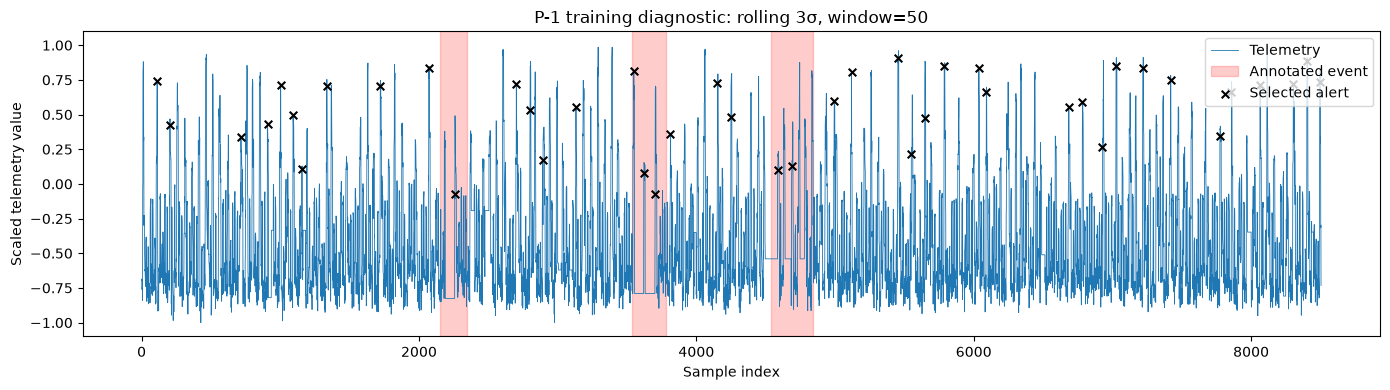

In [27]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(signal, linewidth=0.6, label="Telemetry")

for i, (start, end) in enumerate(sorted(intervals)):
    ax.axvspan(
        start, end,
        color="red",
        alpha=0.2,
        label="Annotated event" if i == 0 else None,
    )

ax.scatter(
    alert_indices,
    signal[alert_indices],
    color="black",
    marker="x",
    s=30,
    label="Selected alert",
    zorder=3,
)

ax.set(
    xlabel="Sample index",
    ylabel="Scaled telemetry value",
    title="P-1 training diagnostic: rolling 3σ, window=50",
)
ax.legend()
fig.tight_layout()
plt.show()

On training channel P-1, rolling 3σ with a 50-sample reference window detected 3/3 annotated events under the alert budget, while producing 37 false alerts among 43 selected alerts. This is an exploratory training result, not evidence of generalization.

In [28]:
from satmon.data import parse_intervals

training_results = []

for _, row in train.iterrows():
    channel_array = np.load(
        test_dir / f"{row['chan_id']}.npy",
        allow_pickle=False,
    )
    channel_signal = channel_array[:, 0]

    channel_intervals = parse_intervals(
        row["anomaly_sequences"],
        len(channel_signal),
    )

    channel_scores = rolling_3sigma(
        channel_signal,
        window_size=50,
    )
    channel_candidates = channel_scores.loc[
        channel_scores["is_candidate"]
    ]

    result = evaluate_channel(
        sample_indices=channel_candidates.index.to_numpy(),
        scores=channel_candidates["score"].to_numpy(),
        intervals=channel_intervals,
        suppression_distance=10,
    )

    training_results.append({
        "channel": row["chan_id"],
        "spacecraft": row["spacecraft"],
        "n_events": result["n_events"],
        "n_detected_events": result["n_detected_events"],
        "n_missed_events": result["n_missed_events"],
        "n_selected_alerts": len(result["selected_alerts"]),
        "n_false_alerts": result["n_false_alerts"],
        "event_recall_at_5": result["event_recall_at_5"],
    })

training_results = pd.DataFrame(training_results)

total_events = int(training_results["n_events"].sum())
total_detected = int(training_results["n_detected_events"].sum())

assert len(training_results) == 48
assert total_events == 65

print("Training channels:", len(training_results))
print("Detected events:", total_detected)
print("Total events:", total_events)
print("Training Event Recall@5:", total_detected / total_events)
print("Selected alerts:", training_results["n_selected_alerts"].sum())
print("False alerts:", training_results["n_false_alerts"].sum())

display(
    training_results.sort_values(
        ["event_recall_at_5", "channel"]
    )
)

Training channels: 48
Detected events: 58
Total events: 65
Training Event Recall@5: 0.8923076923076924
Selected alerts: 1221
False alerts: 1019


,channel,spacecraft,n_events,n_detected_events,n_missed_events,n_selected_alerts,n_false_alerts,event_recall_at_5
8,C-2,MSL,2,0,2,10,10,0.0
20,M-4,MSL,1,0,1,10,10,0.0
43,E-10,SMAP,2,1,1,44,43,0.5
19,E-11,SMAP,2,1,1,44,43,0.5
21,T-1,SMAP,2,1,1,45,37,0.5
0,T-8,MSL,2,1,1,10,8,0.5
13,A-3,SMAP,1,1,0,42,40,1.0
22,A-4,SMAP,1,1,0,41,40,1.0
36,A-5,SMAP,1,1,0,17,16,1.0
10,A-6,SMAP,1,1,0,13,12,1.0


In [29]:
display(
    training_results.loc[
        training_results["n_missed_events"] > 0
    ].sort_values(
        ["n_missed_events", "channel"],
        ascending=[False, True],
    )
)

,channel,spacecraft,n_events,n_detected_events,n_missed_events,n_selected_alerts,n_false_alerts,event_recall_at_5
8,C-2,MSL,2,0,2,10,10,0.0
43,E-10,SMAP,2,1,1,44,43,0.5
19,E-11,SMAP,2,1,1,44,43,0.5
20,M-4,MSL,1,0,1,10,10,0.0
21,T-1,SMAP,2,1,1,45,37,0.5
0,T-8,MSL,2,1,1,10,8,0.5


In [30]:
channel_id = "C-2"
row = train.loc[train["chan_id"] == channel_id].iloc[0]

channel_signal = np.load(
    test_dir / f"{channel_id}.npy",
    allow_pickle=False,
)[:, 0]

channel_intervals = parse_intervals(
    row["anomaly_sequences"],
    len(channel_signal),
)

scored = rolling_3sigma(channel_signal, window_size=50)
candidates = scored.loc[scored["is_candidate"]]

result = evaluate_channel(
    candidates.index.to_numpy(),
    candidates["score"].to_numpy(),
    channel_intervals,
    suppression_distance=10,
)

selected = np.asarray(result["selected_alerts"], dtype=int)

for start, end in channel_intervals:
    event_scores = scored.loc[start:end, "score"]

    candidate_count = (
        (candidates.index >= start) & (candidates.index <= end)
    ).sum()

    selected_count = (
        (selected >= start) & (selected <= end)
    ).sum()

    print({
        "event": (start, end),
        "max_score": event_scores.max(),
        "candidate_count": int(candidate_count),
        "selected_count": int(selected_count),
    })

{'event': (290, 390), 'max_score': np.float64(5.05530462611728), 'candidate_count': 4, 'selected_count': 0}
{'event': (1540, 1575), 'max_score': np.float64(2.120923923305371), 'candidate_count': 0, 'selected_count': 0}


In [31]:
candidate_details = candidates.copy()
candidate_details["block"] = candidate_details.index // 1000
candidate_details["inside_event"] = [
    any(start <= t <= end for start, end in channel_intervals)
    for t in candidate_details.index
]
candidate_details["selected"] = candidate_details.index.isin(selected)

display(
    candidate_details.loc[candidate_details["block"] == 0]
    .sort_values("score", ascending=False)
)

,score,is_candidate,block,inside_event,selected
sample_index,,,,,
208,1.797693e+308,True,0,False,True
658,1.979222e+01,True,0,False,True
863,9.302537e+00,True,0,False,True
209,7.857143e+00,True,0,False,False
443,7.687629e+00,True,0,False,True
224,7.142393e+00,True,0,False,True
225,6.893906e+00,True,0,False,False
659,6.621240e+00,True,0,False,False
226,5.741723e+00,True,0,False,False


C-2 exhibited both candidate-generation and alert-selection failures: one event produced no scores above 3, while the other produced four candidates but no selected alerts. The latter requires examining ranking and suppression to identify the cause.

In [32]:
block_candidates = candidates.loc[
    candidates.index // 1000 == 0
].copy()

block_candidates["inside_first_event"] = (
    (block_candidates.index >= 290)
    & (block_candidates.index <= 390)
)
block_candidates["selected"] = block_candidates.index.isin(selected)

block_candidates["near_selected_alert"] = [
    any(abs(int(t) - int(chosen)) <= 10 for chosen in selected
        if chosen // 1000 == 0)
    for t in block_candidates.index
]

display(block_candidates.sort_values("score", ascending=False))

,score,is_candidate,inside_first_event,selected,near_selected_alert
sample_index,,,,,
208,1.797693e+308,True,False,True,True
658,1.979222e+01,True,False,True,True
863,9.302537e+00,True,False,True,True
209,7.857143e+00,True,False,False,True
443,7.687629e+00,True,False,True,True
224,7.142393e+00,True,False,True,True
225,6.893906e+00,True,False,False,True
659,6.621240e+00,True,False,False,True
226,5.741723e+00,True,False,False,True


C-2’s first event was missed because five higher-scoring candidates outside annotated events exhausted the block’s alert budget. Its second event was missed because no sample exceeded the fixed 3σ threshold. These demonstrate ranking and candidate-generation failures, respectively.

In [33]:
import json
from pathlib import Path

output_dir = Path("../results/baseline_training")
output_dir.mkdir(parents=True, exist_ok=True)

training_results.to_csv(
    output_dir / "channel_results.csv",
    index=False,
)

summary = {
    "split": "train",
    "method": "rolling_3sigma",
    "reference_window": 50,
    "reference": "previous samples, excluding current",
    "standard_deviation_ddof": 0,
    "candidate_rule": "score > 3",
    "suppression_distance": 10,
    "suppression_scope": "within each block",
    "samples_per_block": 1000,
    "max_alerts_per_block": 5,
    "partial_final_block": "same five-alert cap",
    "event_endpoints": "inclusive",
    "event_matching": "selected alert index lies inside event",
    "n_channels": len(training_results),
    "n_events": int(training_results["n_events"].sum()),
    "n_detected_events": int(
        training_results["n_detected_events"].sum()
    ),
    "n_selected_alerts": int(
        training_results["n_selected_alerts"].sum()
    ),
    "n_false_alerts": int(
        training_results["n_false_alerts"].sum()
    ),
}

summary["event_recall_at_5"] = (
    summary["n_detected_events"] / summary["n_events"]
)

(output_dir / "summary.json").write_text(
    json.dumps(summary, indent=2) + "\n",
    encoding="utf-8",
)

print("Saved:", output_dir.resolve())

Saved: C:\dev\satmon\satmon\results\baseline_training


In [34]:
from satmon.features import make_channel_examples

channel_tables = []

for _, row in train.iterrows():
    channel_array = np.load(
        test_dir / f"{row['chan_id']}.npy",
        allow_pickle=False,
    )
    channel_signal = channel_array[:, 0]

    channel_intervals = parse_intervals(
        row["anomaly_sequences"],
        len(channel_signal),
    )

    channel_examples = make_channel_examples(
        signal=channel_signal,
        intervals=channel_intervals,
        channel_id=row["chan_id"],
        window_size=50,
    )

    # Move sample_index into a column before combining channels.
    channel_tables.append(channel_examples.reset_index())

training_examples = pd.concat(channel_tables, ignore_index=True)

assert training_examples["channel_id"].nunique() == 48
assert not training_examples.duplicated(
    ["channel_id", "sample_index"]
).any()
assert not training_examples.isna().any().any()
assert set(training_examples["label"].unique()) == {0, 1}

print("Training rows:", len(training_examples))
print("Label counts:")
print(training_examples["label"].value_counts().sort_index())
print("Feature columns:", training_examples.columns.tolist())

Training rows: 297891
Label counts:
label
0    260024
1     37867
Name: count, dtype: int64
Feature columns: ['sample_index', 'value', 'delta', 'rolling_mean', 'rolling_std', 'label', 'channel_id']


In [35]:
feature_columns = [
    "value",
    "delta",
    "rolling_mean",
    "rolling_std",
]

X_train = training_examples[feature_columns].copy()
y_train = training_examples["label"].copy()

assert np.isfinite(X_train.to_numpy()).all()
assert X_train.index.equals(y_train.index)

print("Feature matrix:", X_train.shape)
print("Target vector:", y_train.shape)

Feature matrix: (297891, 4)
Target vector: (297891,)


In [36]:
from satmon.models import make_logistic_pipeline

logistic = make_logistic_pipeline(C=1.0)
logistic.fit(X_train, y_train)

print("Classes:", logistic.named_steps["model"].classes_)
print("Iterations:", logistic.named_steps["model"].n_iter_)

Classes: [0 1]
Iterations: [8]


In [37]:
coefficient_table = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": logistic.named_steps["model"].coef_[0],
})

display(coefficient_table)

print(
    "Intercept:",
    logistic.named_steps["model"].intercept_[0],
)

,feature,coefficient
0,value,0.140994
1,delta,-0.005683
2,rolling_mean,0.136633
3,rolling_std,0.038973


Intercept: -1.9258109215365748


In [38]:
positive_column = np.flatnonzero(
    logistic.named_steps["model"].classes_ == 1
).item()

training_probabilities = logistic.predict_proba(X_train)[
    :, positive_column
]

print(pd.Series(training_probabilities).describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))
print(
    "Candidates above 0.5:",
    int((training_probabilities > 0.5).sum()),
)

count    297891.000000
mean          0.127140
std           0.022908
min           0.114230
50%           0.125688
90%           0.136827
95%           0.136827
99%           0.137940
max           0.999984
dtype: float64
Candidates above 0.5: 186


In [39]:
training_scored = training_examples.copy()
training_scored["score"] = training_probabilities

logistic_results = []

for channel_id, channel_rows in training_scored.groupby("channel_id"):
    annotation = train.loc[
        train["chan_id"] == channel_id
    ].iloc[0]

    channel_intervals = parse_intervals(
        annotation["anomaly_sequences"],
        int(annotation["num_values"]),
    )

    candidates = channel_rows.loc[channel_rows["score"] > 0.5]

    result = evaluate_channel(
        sample_indices=candidates["sample_index"].to_numpy(),
        scores=candidates["score"].to_numpy(),
        intervals=channel_intervals,
        suppression_distance=10,
    )

    logistic_results.append({
        "channel": channel_id,
        "n_events": result["n_events"],
        "n_detected_events": result["n_detected_events"],
        "n_selected_alerts": len(result["selected_alerts"]),
        "n_false_alerts": result["n_false_alerts"],
    })

logistic_results = pd.DataFrame(logistic_results)

detected = int(logistic_results["n_detected_events"].sum())
total = int(logistic_results["n_events"].sum())

print("Detected events:", detected, "/", total)
print("Training Event Recall@5:", detected / total)
print("Selected alerts:", logistic_results["n_selected_alerts"].sum())
print("False alerts:", logistic_results["n_false_alerts"].sum())

Detected events: 1 / 65
Training Event Recall@5: 0.015384615384615385
Selected alerts: 10
False alerts: 2


In [40]:
validation_tables = []

for _, row in validation.iterrows():
    channel_signal = np.load(
        test_dir / f"{row['chan_id']}.npy",
        allow_pickle=False,
    )[:, 0]

    channel_intervals = parse_intervals(
        row["anomaly_sequences"],
        len(channel_signal),
    )

    examples = make_channel_examples(
        signal=channel_signal,
        intervals=channel_intervals,
        channel_id=row["chan_id"],
        window_size=50,
    ).reset_index()

    # Match the baseline's first eligible prediction index.
    examples = examples.loc[examples["sample_index"] >= 50].copy()
    validation_tables.append(examples)

validation_examples = pd.concat(
    validation_tables,
    ignore_index=True,
)

assert validation_examples["channel_id"].nunique() == 16
assert not validation_examples.duplicated(
    ["channel_id", "sample_index"]
).any()
assert np.isfinite(
    validation_examples[feature_columns].to_numpy()
).all()

validation_examples["score"] = logistic.predict_proba(
    validation_examples[feature_columns]
)[:, positive_column]

print("Validation rows:", len(validation_examples))
print("Validation channels:", validation_examples["channel_id"].nunique())
print(validation_examples["score"].describe())

Validation rows: 101715
Validation channels: 16
count    101715.000000
mean          0.124987
std           0.007539
min           0.117575
25%           0.117592
50%           0.122156
75%           0.132131
max           0.143265
Name: score, dtype: float64


In [41]:
thresholds = [0.0, 0.12, 0.13, 0.14, 0.5]

In [42]:
threshold_results = []

for threshold in thresholds:
    total_events = 0
    total_detected = 0
    total_alerts = 0
    total_false_alerts = 0

    for channel_id, rows in validation_examples.groupby("channel_id"):
        annotation = validation.loc[
            validation["chan_id"] == channel_id
        ].iloc[0]

        events = parse_intervals(
            annotation["anomaly_sequences"],
            int(annotation["num_values"]),
        )

        candidates = rows.loc[rows["score"] > threshold]

        result = evaluate_channel(
            sample_indices=candidates["sample_index"].to_numpy(),
            scores=candidates["score"].to_numpy(),
            intervals=events,
            suppression_distance=10,
        )

        total_events += result["n_events"]
        total_detected += result["n_detected_events"]
        total_alerts += len(result["selected_alerts"])
        total_false_alerts += result["n_false_alerts"]

    threshold_results.append({
        "threshold": threshold,
        "events": total_events,
        "detected": total_detected,
        "event_recall_at_5": total_detected / total_events,
        "selected_alerts": total_alerts,
        "false_alerts": total_false_alerts,
    })

threshold_results = pd.DataFrame(threshold_results)
display(threshold_results)

,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts
0,0.00,19,15,0.789474,550,450
1,0.12,19,15,0.789474,370,273
2,0.13,19,12,0.631579,299,224
3,0.14,19,1,0.052632,10,1
4,0.50,19,0,0.000000,0,0


In [43]:
baseline_validation_rows = []

for _, row in validation.iterrows():
    channel_signal = np.load(
        test_dir / f"{row['chan_id']}.npy",
        allow_pickle=False,
    )[:, 0]

    events = parse_intervals(
        row["anomaly_sequences"],
        len(channel_signal),
    )

    scored = rolling_3sigma(channel_signal, window_size=50)
    candidates = scored.loc[scored["is_candidate"]]

    result = evaluate_channel(
        sample_indices=candidates.index.to_numpy(),
        scores=candidates["score"].to_numpy(),
        intervals=events,
        suppression_distance=10,
    )

    baseline_validation_rows.append({
        "channel": row["chan_id"],
        "spacecraft": row["spacecraft"],
        "n_events": result["n_events"],
        "n_detected_events": result["n_detected_events"],
        "n_missed_events": result["n_missed_events"],
        "n_selected_alerts": len(result["selected_alerts"]),
        "n_false_alerts": result["n_false_alerts"],
    })

baseline_validation = pd.DataFrame(baseline_validation_rows)

n_events = int(baseline_validation["n_events"].sum())
n_detected = int(baseline_validation["n_detected_events"].sum())
n_false = int(baseline_validation["n_false_alerts"].sum())

assert len(baseline_validation) == 16
assert n_events == 19

print("Detected events:", n_detected, "/", n_events)
print("Validation Event Recall@5:", n_detected / n_events)
print("Selected alerts:", baseline_validation["n_selected_alerts"].sum())
print("False alerts:", n_false)
print("Secondary assumed cost:", 10 * (n_events - n_detected) + n_false)

Detected events: 17 / 19
Validation Event Recall@5: 0.8947368421052632
Selected alerts: 343
False alerts: 267
Secondary assumed cost: 287


In [44]:
import importlib
import satmon.models
import satmon.evaluation


importlib.reload(satmon.evaluation)
importlib.reload(satmon.models)

from satmon.models import make_random_forest

forest = make_random_forest()
forest.fit(X_train, y_train)

print("Trees fitted:", len(forest.estimators_))

Trees fitted: 100


In [45]:
from satmon.models import make_random_forest

forest = make_random_forest()
forest.fit(X_train, y_train)

print("Trees fitted:", len(forest.estimators_))

Trees fitted: 100


In [46]:
forest_positive_column = np.flatnonzero(
    forest.classes_ == 1
).item()

forest_validation = validation_examples.copy()
forest_validation["score"] = forest.predict_proba(
    forest_validation[feature_columns]
)[:, forest_positive_column]

In [47]:
forest_threshold_results = []

for threshold in [0.0, 0.12, 0.25, 0.5, 0.75]:
    total_events = 0
    total_detected = 0
    total_alerts = 0
    total_false_alerts = 0

    for channel_id, rows in forest_validation.groupby("channel_id"):
        annotation = validation.loc[
            validation["chan_id"] == channel_id
        ].iloc[0]

        events = parse_intervals(
            annotation["anomaly_sequences"],
            int(annotation["num_values"]),
        )

        candidates = rows.loc[rows["score"] > threshold]

        result = evaluate_channel(
            sample_indices=candidates["sample_index"].to_numpy(),
            scores=candidates["score"].to_numpy(),
            intervals=events,
            suppression_distance=10,
        )

        total_events += result["n_events"]
        total_detected += result["n_detected_events"]
        total_alerts += len(result["selected_alerts"])
        total_false_alerts += result["n_false_alerts"]

    forest_threshold_results.append({
        "threshold": threshold,
        "events": total_events,
        "detected": total_detected,
        "event_recall_at_5": total_detected / total_events,
        "selected_alerts": total_alerts,
        "false_alerts": total_false_alerts,
        "secondary_cost": (
            10 * (total_events - total_detected)
            + total_false_alerts
        ),
    })

forest_threshold_results = pd.DataFrame(forest_threshold_results)
display(forest_threshold_results)

,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
0,0.00,19,16,0.842105,550,454,484
1,0.12,19,16,0.842105,333,238,268
2,0.25,19,15,0.789474,191,133,173
3,0.50,19,10,0.526316,152,106,196
4,0.75,19,5,0.263158,81,63,203


In [48]:
import importlib
import satmon.models

importlib.reload(satmon.models)

from satmon.models import make_pca_logistic_pipeline

pca_models = {}

for n_components in [2, 3]:
    model = make_pca_logistic_pipeline(n_components, C=1.0)
    model.fit(X_train, y_train)
    pca_models[n_components] = model

    explained = model.named_steps["pca"].explained_variance_ratio_

    print(f"{n_components} components")
    print("Explained variance ratios:", explained)
    print("Total retained variance:", explained.sum())

2 components
Explained variance ratios: [0.54310216 0.250016  ]
Total retained variance: 0.7931181555462219
3 components
Explained variance ratios: [0.54310216 0.250016   0.20121708]
Total retained variance: 0.9943352352891671


In [49]:
pca_validation_results = []

for n_components, model in pca_models.items():
    positive_column = np.flatnonzero(
        model.named_steps["model"].classes_ == 1
    ).item()

    scored_rows = validation_examples.copy()
    scored_rows["score"] = model.predict_proba(
        scored_rows[feature_columns]
    )[:, positive_column]

    for threshold in [0.0, 0.12, 0.13, 0.14, 0.5]:
        n_events = 0
        n_detected = 0
        n_alerts = 0
        n_false = 0

        for channel_id, rows in scored_rows.groupby("channel_id"):
            annotation = validation.loc[
                validation["chan_id"] == channel_id
            ].iloc[0]

            events = parse_intervals(
                annotation["anomaly_sequences"],
                int(annotation["num_values"]),
            )

            candidates = rows.loc[rows["score"] > threshold]

            result = evaluate_channel(
                sample_indices=candidates["sample_index"].to_numpy(),
                scores=candidates["score"].to_numpy(),
                intervals=events,
                suppression_distance=10,
            )

            n_events += result["n_events"]
            n_detected += result["n_detected_events"]
            n_alerts += len(result["selected_alerts"])
            n_false += result["n_false_alerts"]

        pca_validation_results.append({
            "components": n_components,
            "threshold": threshold,
            "events": n_events,
            "detected": n_detected,
            "event_recall_at_5": n_detected / n_events,
            "selected_alerts": n_alerts,
            "false_alerts": n_false,
            "secondary_cost": 10 * (n_events - n_detected) + n_false,
        })

pca_validation_results = pd.DataFrame(pca_validation_results)
display(pca_validation_results)

,components,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
0,2,0.00,19,15,0.789474,550,446,486
1,2,0.12,19,15,0.789474,374,271,311
2,2,0.13,19,14,0.736842,302,221,271
3,2,0.14,19,2,0.105263,16,6,176
4,2,0.50,19,0,0.000000,0,0,190
5,3,0.00,19,15,0.789474,550,450,490
6,3,0.12,19,15,0.789474,370,273,313
7,3,0.13,19,12,0.631579,298,224,294
8,3,0.14,19,1,0.052632,10,1,181
9,3,0.50,19,0,0.000000,0,0,190


At C=1 and the tested thresholds, PCA did not improve validation Event Recall@5 over original-feature Logistic Regression. Two components retained 79.3% of training variance and reduced false alerts from 273 to 271 at equal recall; three components retained 99.4% and matched the original aggregate results. We provisionally retain the original features because the observed benefit does not justify reduced interpretability.

In [50]:
pca_output_dir = Path("../results/pca_validation")
pca_output_dir.mkdir(parents=True, exist_ok=True)

pca_validation_results.to_csv(
    pca_output_dir / "threshold_results.csv",
    index=False,
)

In [51]:
from satmon.evaluation import evaluate_scored_channels

evaluate_scored_channels(
    validation_examples,
    validation,
    threshold=0.12,
)

{'threshold': 0.12,
 'events': 19,
 'detected': 15,
 'event_recall_at_5': 0.7894736842105263,
 'selected_alerts': 370,
 'false_alerts': 273,
 'secondary_cost': 313}

In [52]:
logistic_tuning_rows = []
logistic_candidates = {}

for C in [0.01, 1.0, 100.0]:
    model = make_logistic_pipeline(C=C)
    model.fit(X_train, y_train)
    logistic_candidates[C] = model

    positive_column = np.flatnonzero(
        model.named_steps["model"].classes_ == 1
    ).item()

    scored_validation = validation_examples.copy()
    scored_validation["score"] = model.predict_proba(
        scored_validation[feature_columns]
    )[:, positive_column]

    coefficient_norm = float(
        np.linalg.norm(model.named_steps["model"].coef_[0])
    )

    for threshold in [0.0, 0.12, 0.13, 0.14, 0.5]:
        result = evaluate_scored_channels(
            scored_validation,
            validation,
            threshold=threshold,
        )

        logistic_tuning_rows.append({
            "C": C,
            "coefficient_norm": coefficient_norm,
            **result,
        })

logistic_tuning_results = pd.DataFrame(logistic_tuning_rows)

display(
    logistic_tuning_results.sort_values(
        ["detected", "false_alerts", "C"],
        ascending=[False, True, True],
    )
)

,C,coefficient_norm,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
6,1.00,0.200248,0.12,19,15,0.789474,370,273,313
11,100.00,0.200308,0.12,19,15,0.789474,370,273,313
1,0.01,0.194503,0.12,19,15,0.789474,375,278,318
0,0.01,0.194503,0.00,19,15,0.789474,550,450,490
5,1.00,0.200248,0.00,19,15,0.789474,550,450,490
10,100.00,0.200308,0.00,19,15,0.789474,550,450,490
2,0.01,0.194503,0.13,19,12,0.631579,299,224,294
7,1.00,0.200248,0.13,19,12,0.631579,299,224,294
12,100.00,0.200308,0.13,19,12,0.631579,299,224,294
3,0.01,0.194503,0.14,19,1,0.052632,10,1,181


In [53]:
tuning_dir = Path("../results/model_selection")
tuning_dir.mkdir(parents=True, exist_ok=True)

logistic_tuning_results.to_csv(
    tuning_dir / "logistic_validation.csv",
    index=False,
)

selected_logistic = logistic_candidates[1.0]
selected_logistic_threshold = 0.12

In [54]:
import importlib
import satmon.models

importlib.reload(satmon.models)

from satmon.models import make_random_forest

forest_tuning_rows = []
forest_candidates = {}

for depth in [4, 8]:
    for leaf_size in [20, 100]:
        print(f"Fitting depth={depth}, min_samples_leaf={leaf_size}")

        model = make_random_forest(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            n_estimators=100,
        )
        model.fit(X_train, y_train)
        forest_candidates[(depth, leaf_size)] = model

        positive_column = np.flatnonzero(
            model.classes_ == 1
        ).item()

        scored_validation = validation_examples.copy()
        scored_validation["score"] = model.predict_proba(
            scored_validation[feature_columns]
        )[:, positive_column]

        for threshold in [0.0, 0.12, 0.25, 0.5, 0.75]:
            result = evaluate_scored_channels(
                scored_validation,
                validation,
                threshold=threshold,
            )

            forest_tuning_rows.append({
                "max_depth": depth,
                "min_samples_leaf": leaf_size,
                "n_estimators": 100,
                **result,
            })

forest_tuning_results = pd.DataFrame(forest_tuning_rows)

display(
    forest_tuning_results.sort_values(
        ["detected", "false_alerts", "max_depth", "min_samples_leaf"],
        ascending=[False, True, True, False],
    )
)

Fitting depth=4, min_samples_leaf=20
Fitting depth=4, min_samples_leaf=100
Fitting depth=8, min_samples_leaf=20
Fitting depth=8, min_samples_leaf=100


,max_depth,min_samples_leaf,n_estimators,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
16,8,100,100,0.12,19,16,0.842105,326,232,262
11,8,20,100,0.12,19,16,0.842105,333,238,268
10,8,20,100,0.00,19,16,0.842105,550,454,484
15,8,100,100,0.00,19,16,0.842105,550,455,485
17,8,100,100,0.25,19,15,0.789474,187,129,169
12,8,20,100,0.25,19,15,0.789474,191,133,173
6,4,100,100,0.12,19,15,0.789474,322,238,278
1,4,20,100,0.12,19,15,0.789474,324,238,278
5,4,100,100,0.00,19,15,0.789474,550,457,497
0,4,20,100,0.00,19,15,0.789474,550,459,499


In [55]:
forest_tuning_results.to_csv(
    tuning_dir / "forest_validation.csv",
    index=False,
)

selected_forest = forest_candidates[(8, 100)]
selected_forest_threshold = 0.12

In [56]:
def assemble_split_examples(
    split_annotations,
    window_size,
    first_prediction_index=100,
):
    tables = []

    for _, row in split_annotations.iterrows():
        channel_signal = np.load(
            test_dir / f"{row['chan_id']}.npy",
            allow_pickle=False,
        )[:, 0]

        events = parse_intervals(
            row["anomaly_sequences"],
            len(channel_signal),
        )

        examples = make_channel_examples(
            signal=channel_signal,
            intervals=events,
            channel_id=row["chan_id"],
            window_size=window_size,
        ).reset_index()

        examples = examples.loc[
            examples["sample_index"] >= first_prediction_index
        ].copy()

        tables.append(examples)

    combined = pd.concat(tables, ignore_index=True)

    assert not combined.duplicated(
        ["channel_id", "sample_index"]
    ).any()
    assert np.isfinite(combined[feature_columns].to_numpy()).all()
    assert combined["sample_index"].ge(first_prediction_index).all()

    return combined

In [57]:
window_tables = {}

for window_size in [50, 100]:
    window_tables[window_size] = {
        "train": assemble_split_examples(train, window_size),
        "validation": assemble_split_examples(validation, window_size),
    }

    print(
        window_size,
        "training rows:",
        len(window_tables[window_size]["train"]),
        "validation rows:",
        len(window_tables[window_size]["validation"]),
    )

50 training rows: 295443 validation rows: 100915
100 training rows: 295443 validation rows: 100915


In [58]:
window_comparison_rows = []
window_models = {}

for window_size in [50, 100]:
    training_table = window_tables[window_size]["train"]
    validation_table = window_tables[window_size]["validation"]

    models = {
        "logistic": (
            make_logistic_pipeline(C=1.0),
            [0.0, 0.12, 0.13, 0.14, 0.5],
        ),
        "forest": (
            make_random_forest(
                max_depth=8,
                min_samples_leaf=100,
                n_estimators=100,
            ),
            [0.0, 0.12, 0.25, 0.5, 0.75],
        ),
    }

    for model_name, (model, thresholds) in models.items():
        model.fit(
            training_table[feature_columns],
            training_table["label"],
        )
        window_models[(window_size, model_name)] = model

        positive_column = np.flatnonzero(
            model.classes_ == 1
        ).item()

        scored_validation = validation_table.copy()
        scored_validation["score"] = model.predict_proba(
            validation_table[feature_columns]
        )[:, positive_column]

        for threshold in thresholds:
            result = evaluate_scored_channels(
                scored_validation,
                validation,
                threshold=threshold,
            )

            window_comparison_rows.append({
                "window_size": window_size,
                "model": model_name,
                **result,
            })

window_comparison_results = pd.DataFrame(window_comparison_rows)

best_per_window = (
    window_comparison_results
    .sort_values(
        ["detected", "false_alerts", "threshold"],
        ascending=[False, True, True],
    )
    .groupby(["model", "window_size"], sort=False)
    .head(1)
)

display(best_per_window)

,window_size,model,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
17,100,forest,0.25,19,16,0.842105,233,177,207
6,50,forest,0.12,19,16,0.842105,330,237,267
12,100,logistic,0.13,19,15,0.789474,334,242,282
1,50,logistic,0.12,19,15,0.789474,384,285,325


In [59]:
baseline_window_rows = []

for window_size in [50, 100]:
    total_events = 0
    total_detected = 0
    total_alerts = 0
    total_false = 0

    for _, row in validation.iterrows():
        channel_signal = np.load(
            test_dir / f"{row['chan_id']}.npy",
            allow_pickle=False,
        )[:, 0]

        events = parse_intervals(
            row["anomaly_sequences"],
            len(channel_signal),
        )

        scored = rolling_3sigma(channel_signal, window_size)
        candidates = scored.loc[
            (scored.index >= 100) & scored["is_candidate"]
        ]

        result = evaluate_channel(
            candidates.index.to_numpy(),
            candidates["score"].to_numpy(),
            events,
            suppression_distance=10,
        )

        total_events += result["n_events"]
        total_detected += result["n_detected_events"]
        total_alerts += len(result["selected_alerts"])
        total_false += result["n_false_alerts"]

    baseline_window_rows.append({
        "window_size": window_size,
        "events": total_events,
        "detected": total_detected,
        "event_recall_at_5": total_detected / total_events,
        "selected_alerts": total_alerts,
        "false_alerts": total_false,
        "secondary_cost": 10 * (total_events - total_detected)
                          + total_false,
    })

baseline_window_results = pd.DataFrame(baseline_window_rows)
display(baseline_window_results)

,window_size,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
0,50,19,17,0.894737,343,267,287
1,100,19,17,0.894737,251,181,201


In [60]:
pca_window100_rows = []
pca_window100_models = {}

training_table = window_tables[100]["train"]
validation_table = window_tables[100]["validation"]

for n_components in [2, 3]:
    model = make_pca_logistic_pipeline(n_components, C=1.0)
    model.fit(
        training_table[feature_columns],
        training_table["label"],
    )
    pca_window100_models[n_components] = model

    scored_validation = validation_table.copy()
    positive_column = np.flatnonzero(model.classes_ == 1).item()

    scored_validation["score"] = model.predict_proba(
        validation_table[feature_columns]
    )[:, positive_column]

    retained_variance = float(
        model.named_steps["pca"].explained_variance_ratio_.sum()
    )

    for threshold in [0.0, 0.12, 0.13, 0.14, 0.5]:
        result = evaluate_scored_channels(
            scored_validation,
            validation,
            threshold=threshold,
        )

        pca_window100_rows.append({
            "components": n_components,
            "retained_variance": retained_variance,
            **result,
        })

pca_window100_results = pd.DataFrame(pca_window100_rows)

display(
    pca_window100_results.sort_values(
        ["detected", "false_alerts", "components"],
        ascending=[False, True, True],
    )
)

,components,retained_variance,threshold,events,detected,event_recall_at_5,selected_alerts,false_alerts,secondary_cost
2,2,0.83735,0.13,19,15,0.789474,319,227,267
7,3,0.99040,0.13,19,15,0.789474,334,242,282
0,2,0.83735,0.00,19,15,0.789474,550,447,487
1,2,0.83735,0.12,19,15,0.789474,550,447,487
5,3,0.99040,0.00,19,15,0.789474,550,451,491
6,3,0.99040,0.12,19,15,0.789474,550,451,491
8,3,0.99040,0.14,19,14,0.736842,281,209,259
3,2,0.83735,0.14,19,12,0.631579,301,222,292
4,2,0.83735,0.50,19,0,0.000000,0,0,190
9,3,0.99040,0.50,19,0,0.000000,0,0,190


At window 100, two-component PCA retained 83.7% of training variance and reduced validation false alerts from 242 to 227 at unchanged Event Recall@5 (15/19). Three components matched the original aggregate results. PCA did not change the preferred approach: rolling 3σ achieved higher recall and fewer false alerts. We retain original-feature Logistic Regression for direct feature interpretation.

In [61]:
window_comparison_results.to_csv(
    tuning_dir / "supervised_window_validation.csv", index=False
)
baseline_window_results.to_csv(
    tuning_dir / "baseline_window_validation.csv", index=False
)
pca_window100_results.to_csv(
    tuning_dir / "pca_window100_validation.csv", index=False
)

## Final held-out evaluation

Settings were selected using training and validation channels only.
Window size and first prediction index are both 100.
Models remain fitted on training channels only.
Test results will not be used to tune the procedure.

In [62]:
test_examples = assemble_split_examples(
    test,
    window_size=100,
    first_prediction_index=100,
)

assert set(test_examples["channel_id"]) == set(test["chan_id"])
assert set(test_examples["channel_id"]).isdisjoint(train["chan_id"])
assert set(test_examples["channel_id"]).isdisjoint(validation["chan_id"])

print("Test channels:", test_examples["channel_id"].nunique())
print("Test feature rows:", len(test_examples))

Test channels: 16
Test feature rows: 96988


In [63]:
final_channel_rows = []
final_event_rows = []
final_alert_rows = []

final_models = {
    "logistic": (window_models[(100, "logistic")], 0.13),
    "forest": (window_models[(100, "forest")], 0.25),
}

for _, annotation in test.iterrows():
    channel_id = annotation["chan_id"]

    events = parse_intervals(
        annotation["anomaly_sequences"],
        int(annotation["num_values"]),
    )
    event_types = [
        value.strip()
        for value in annotation["class"].strip("[]").split(",")
        if value.strip()
    ]
    assert len(events) == len(event_types)

    rows = test_examples.loc[
        test_examples["channel_id"] == channel_id
    ]

    # Baseline: same window and eligible timeline as supervised models.
    channel_signal = np.load(
        test_dir / f"{channel_id}.npy",
        allow_pickle=False,
    )[:, 0]

    baseline_scores = rolling_3sigma(channel_signal, window_size=100)
    baseline_candidates = baseline_scores.loc[
        (baseline_scores.index >= 100)
        & baseline_scores["is_candidate"]
    ]

    method_candidates = {
        "baseline": (
            baseline_candidates.index.to_numpy(),
            baseline_candidates["score"].to_numpy(),
        )
    }

    for name, (model, threshold) in final_models.items():
        positive_column = np.flatnonzero(model.classes_ == 1).item()
        probabilities = model.predict_proba(
            rows[feature_columns]
        )[:, positive_column]

        candidate_mask = probabilities > threshold

        method_candidates[name] = (
            rows["sample_index"].to_numpy()[candidate_mask],
            probabilities[candidate_mask],
        )

    for name, (indices, scores) in method_candidates.items():
        result = evaluate_channel(
            indices,
            scores,
            events,
            suppression_distance=10,
        )

        final_channel_rows.append({
            "method": name,
            "channel": channel_id,
            "spacecraft": annotation["spacecraft"],
            "n_samples": len(channel_signal),
            "n_scored_samples": len(rows),
            "n_events": result["n_events"],
            "n_detected_events": result["n_detected_events"],
            "n_missed_events": result["n_missed_events"],
            "n_selected_alerts": len(result["selected_alerts"]),
            "n_false_alerts": result["n_false_alerts"],
        })

        for event_id, ((start, end), event_type, detected) in enumerate(
            zip(events, event_types, result["event_detected"])
        ):
            final_event_rows.append({
                "method": name,
                "channel": channel_id,
                "spacecraft": annotation["spacecraft"],
                "event_id": event_id,
                "start": start,
                "end": end,
                "event_type": event_type,
                "detected": detected,
            })

        for sample_index in result["selected_alerts"]:
            final_alert_rows.append({
                "method": name,
                "channel": channel_id,
                "sample_index": sample_index,
            })

final_channels = pd.DataFrame(final_channel_rows)
final_events = pd.DataFrame(final_event_rows)
final_alerts = pd.DataFrame(
    final_alert_rows,
    columns=["method", "channel", "sample_index"],
)

final_summary = final_channels.groupby("method")[
    [
        "n_events",
        "n_detected_events",
        "n_missed_events",
        "n_selected_alerts",
        "n_false_alerts",
    ]
].sum()

final_summary["event_recall_at_5"] = (
    final_summary["n_detected_events"] / final_summary["n_events"]
)
final_summary["secondary_cost"] = (
    10 * final_summary["n_missed_events"]
    + final_summary["n_false_alerts"]
)

display(final_summary)

,n_events,n_detected_events,n_missed_events,n_selected_alerts,n_false_alerts,event_recall_at_5,secondary_cost
method,,,,,,,
baseline,19,17,2,184,146,0.894737,166
forest,19,15,4,370,297,0.789474,337
logistic,19,13,6,403,316,0.684211,376


In [64]:
final_dir = Path("../results/final_test")
final_dir.mkdir(parents=True, exist_ok=True)

final_channels.to_csv(final_dir / "channels.csv", index=False)
final_events.to_csv(final_dir / "events.csv", index=False)
final_alerts.to_csv(final_dir / "alerts.csv", index=False)
final_summary.to_csv(final_dir / "summary.csv")

print("Saved final test results:", final_dir.resolve())

Saved final test results: C:\dev\satmon\satmon\results\final_test


In [65]:
methods = ["baseline", "forest", "logistic"]

event_counts = final_channels.pivot(
    index="channel",
    columns="method",
    values="n_events",
).reindex(columns=methods).sort_index()

detected_counts = final_channels.pivot(
    index="channel",
    columns="method",
    values="n_detected_events",
).reindex(index=event_counts.index, columns=methods)

assert not event_counts.isna().any().any()
assert not detected_counts.isna().any().any()

for method in methods:
    np.testing.assert_array_equal(
        event_counts[method],
        event_counts["baseline"],
    )

rng = np.random.default_rng(42)
n_bootstrap = 5000
n_channels = len(event_counts)

draws = rng.integers(
    0,
    n_channels,
    size=(n_bootstrap, n_channels),
)

events_array = event_counts.to_numpy()
detected_array = detected_counts.to_numpy()

bootstrap_event_totals = events_array[draws].sum(axis=1)
bootstrap_detected_totals = detected_array[draws].sum(axis=1)

assert (bootstrap_event_totals > 0).all()

bootstrap_recalls = (
    bootstrap_detected_totals / bootstrap_event_totals
)

interval_rows = []

for column, method in enumerate(methods):
    lower, upper = np.quantile(
        bootstrap_recalls[:, column],
        [0.025, 0.975],
    )

    interval_rows.append({
        "method": method,
        "event_recall_at_5": (
            detected_counts[method].sum()
            / event_counts[method].sum()
        ),
        "ci_lower": lower,
        "ci_upper": upper,
    })

recall_intervals = pd.DataFrame(interval_rows)
display(recall_intervals)

difference_rows = []

for other in ["forest", "logistic"]:
    other_column = methods.index(other)

    differences = (
        bootstrap_recalls[:, methods.index("baseline")]
        - bootstrap_recalls[:, other_column]
    )
    lower, upper = np.quantile(differences, [0.025, 0.975])

    difference_rows.append({
        "comparison": f"baseline minus {other}",
        "observed_recall_difference": (
            final_summary.loc["baseline", "event_recall_at_5"]
            - final_summary.loc[other, "event_recall_at_5"]
        ),
        "ci_lower": lower,
        "ci_upper": upper,
    })

paired_differences = pd.DataFrame(difference_rows)
display(paired_differences)

,method,event_recall_at_5,ci_lower,ci_upper
0,baseline,0.894737,0.761905,1.000000
1,forest,0.789474,0.636364,0.941176
2,logistic,0.684211,0.449861,0.888889


,comparison,observed_recall_difference,ci_lower,ci_upper
0,baseline minus forest,0.105263,-0.105263,0.315789
1,baseline minus logistic,0.210526,-0.058824,0.523872


In [66]:
display(paired_differences)

,comparison,observed_recall_difference,ci_lower,ci_upper
0,baseline minus forest,0.105263,-0.105263,0.315789
1,baseline minus logistic,0.210526,-0.058824,0.523872


In [67]:
recall_intervals.to_csv(
    final_dir / "recall_intervals.csv", index=False
)
paired_differences.to_csv(
    final_dir / "paired_recall_differences.csv", index=False
)

In [68]:
spacecraft_summary = final_channels.groupby(
    ["method", "spacecraft"]
).agg(
    n_channels=("channel", "nunique"),
    n_samples=("n_samples", "sum"),
    n_scored_samples=("n_scored_samples", "sum"),
    n_events=("n_events", "sum"),
    n_detected_events=("n_detected_events", "sum"),
    n_false_alerts=("n_false_alerts", "sum"),
).reset_index()

spacecraft_summary["event_recall_at_5"] = (
    spacecraft_summary["n_detected_events"]
    / spacecraft_summary["n_events"]
)

display(spacecraft_summary)

,method,spacecraft,n_channels,n_samples,n_scored_samples,n_events,n_detected_events,n_false_alerts,event_recall_at_5
0,baseline,MSL,6,16786,16186,9,7,45,0.777778
1,baseline,SMAP,10,81802,80802,10,10,101,1.000000
2,forest,MSL,6,16786,16186,9,7,68,0.777778
3,forest,SMAP,10,81802,80802,10,8,229,0.800000
4,logistic,MSL,6,16786,16186,9,7,59,0.777778
5,logistic,SMAP,10,81802,80802,10,6,257,0.600000


In [69]:
spacecraft_interval_rows = []
rng = np.random.default_rng(42)

for spacecraft in ["MSL", "SMAP"]:
    subset = final_channels.loc[
        final_channels["spacecraft"] == spacecraft
    ]

    event_table = subset.pivot(
        index="channel", columns="method", values="n_events"
    ).reindex(columns=methods).sort_index()

    detected_table = subset.pivot(
        index="channel", columns="method",
        values="n_detected_events",
    ).reindex(index=event_table.index, columns=methods)

    draws = rng.integers(
        0, len(event_table),
        size=(5000, len(event_table)),
    )

    event_totals = event_table.to_numpy()[draws].sum(axis=1)
    detected_totals = detected_table.to_numpy()[draws].sum(axis=1)

    assert (event_totals > 0).all()
    recalls = detected_totals / event_totals

    for column, method in enumerate(methods):
        lower, upper = np.quantile(
            recalls[:, column], [0.025, 0.975]
        )

        spacecraft_interval_rows.append({
            "method": method,
            "spacecraft": spacecraft,
            "ci_lower": lower,
            "ci_upper": upper,
        })

spacecraft_intervals = pd.DataFrame(spacecraft_interval_rows)

spacecraft_summary = spacecraft_summary.merge(
    spacecraft_intervals,
    on=["method", "spacecraft"],
    validate="one_to_one",
)

display(spacecraft_summary)

,method,spacecraft,n_channels,n_samples,n_scored_samples,n_events,n_detected_events,n_false_alerts,event_recall_at_5,ci_lower,ci_upper
0,baseline,MSL,6,16786,16186,9,7,45,0.777778,0.500000,1.0
1,baseline,SMAP,10,81802,80802,10,10,101,1.000000,1.000000,1.0
2,forest,MSL,6,16786,16186,9,7,68,0.777778,0.636364,1.0
3,forest,SMAP,10,81802,80802,10,8,229,0.800000,0.500000,1.0
4,logistic,MSL,6,16786,16186,9,7,59,0.777778,0.444444,1.0
5,logistic,SMAP,10,81802,80802,10,6,257,0.600000,0.300000,0.9


In [70]:
spacecraft_summary.to_csv(
    final_dir / "spacecraft_slices.csv",
    index=False,
)

In [71]:
event_outcomes = final_events.pivot(
    index=[
        "channel", "spacecraft", "event_id",
        "start", "end", "event_type",
    ],
    columns="method",
    values="detected",
).reset_index()

display(
    event_outcomes.loc[
        ~event_outcomes[["baseline", "forest", "logistic"]].all(axis=1)
    ]
)

method,channel,spacecraft,event_id,start,end,event_type,baseline,forest,logistic
0,A-9,SMAP,0,4569,8433,contextual,True,True,False
1,D-11,SMAP,0,4270,4330,point,True,False,False
3,D-14,MSL,0,1630,1650,point,True,False,False
8,E-6,SMAP,0,5610,5675,point,True,False,True
10,F-3,SMAP,0,5600,5640,contextual,True,True,False
11,F-7,MSL,0,1250,1450,contextual,False,False,True
14,G-4,SMAP,0,4690,4720,point,True,True,False
15,M-5,MSL,0,1250,1550,contextual,True,True,False
17,T-12,MSL,0,630,750,contextual,False,True,True


In [72]:
miss_diagnostics = []

baseline_misses = event_outcomes.loc[
    ~event_outcomes["baseline"]
]

for _, event in baseline_misses.iterrows():
    channel_id = event["channel"]

    channel_signal = np.load(
        test_dir / f"{channel_id}.npy",
        allow_pickle=False,
    )[:, 0]

    scored = rolling_3sigma(channel_signal, window_size=100)
    scored = scored.loc[scored.index >= 100]

    event_scores = scored.loc[event["start"]:event["end"]]

    selected_indices = final_alerts.loc[
        (final_alerts["method"] == "baseline")
        & (final_alerts["channel"] == channel_id),
        "sample_index",
    ].to_numpy()

    start = int(event["start"])
    end = int(event["end"])

    miss_diagnostics.append({
        "channel": channel_id,
        "start": start,
        "end": end,
        "max_event_score": event_scores["score"].max(),
        "event_candidates": int(
            event_scores["is_candidate"].sum()
        ),
        "selected_in_event": int(
            ((selected_indices >= start)
             & (selected_indices <= end)).sum()
        ),
    })

miss_diagnostics = pd.DataFrame(miss_diagnostics)
display(miss_diagnostics)

,channel,start,end,max_event_score,event_candidates,selected_in_event
0,F-7,1250,1450,3.255825,2,0
1,T-12,630,750,2.470045,0,0


In [73]:
f7_signal = np.load(
    test_dir / "F-7.npy",
    allow_pickle=False,
)[:, 0]

f7_scores = rolling_3sigma(f7_signal, window_size=100)

# The missed event lies in block 1: indices 1000–1999.
f7_candidates = f7_scores.loc[
    (f7_scores.index >= 1000)
    & (f7_scores.index < 2000)
    & f7_scores["is_candidate"]
].copy()

f7_selected = final_alerts.loc[
    (final_alerts["method"] == "baseline")
    & (final_alerts["channel"] == "F-7")
    & (final_alerts["sample_index"] >= 1000)
    & (final_alerts["sample_index"] < 2000),
    "sample_index",
].to_numpy()

f7_candidates["inside_event"] = (
    (f7_candidates.index >= 1250)
    & (f7_candidates.index <= 1450)
)
f7_candidates["selected"] = f7_candidates.index.isin(f7_selected)
f7_candidates["near_selected_alert"] = [
    any(abs(int(t) - int(chosen)) <= 10 for chosen in f7_selected)
    for t in f7_candidates.index
]

display(f7_candidates.sort_values("score", ascending=False))

,score,is_candidate,inside_event,selected,near_selected_alert
sample_index,,,,,
1161,10.676495,True,False,True,True
1737,7.246268,True,False,True,True
1162,7.244883,True,False,False,True
1754,6.791695,True,False,True,True
1753,6.597766,True,False,False,True
1164,5.129228,True,False,False,True
1756,4.995597,True,False,False,True
1169,4.638631,True,False,False,True
1050,4.556161,True,False,True,True


The baseline’s two held-out misses illustrate different limitations. F-7 produced two candidates, but stronger candidates outside the event exhausted the block’s review budget. T-12 produced no candidates because its maximum score, 2.47, remained below the fixed 3σ threshold. These observations identify algorithmic failure stages, not physical causes.

In [74]:
type_summary = final_events.groupby(
    ["method", "event_type"]
).agg(
    n_channels=("channel", "nunique"),
    n_events=("event_id", "size"),
    n_detected_events=("detected", "sum"),
).reset_index()

type_summary["event_recall_at_5"] = (
    type_summary["n_detected_events"] / type_summary["n_events"]
)

display(type_summary)

,method,event_type,n_channels,n_events,n_detected_events,event_recall_at_5
0,baseline,contextual,5,7,5,0.714286
1,baseline,point,11,12,12,1.000000
2,forest,contextual,5,7,6,0.857143
3,forest,point,11,12,9,0.750000
4,logistic,contextual,5,7,4,0.571429
5,logistic,point,11,12,9,0.750000


In [75]:
type_interval_rows = []
rng = np.random.default_rng(42)

for event_type in ["contextual", "point"]:
    subset = final_events.loc[
        final_events["event_type"] == event_type
    ]

    counts = subset.groupby(["channel", "method"]).agg(
        n_events=("detected", "size"),
        n_detected=("detected", "sum"),
    ).reset_index()

    event_table = counts.pivot(
        index="channel", columns="method", values="n_events"
    ).reindex(columns=methods).sort_index()

    detected_table = counts.pivot(
        index="channel", columns="method", values="n_detected"
    ).reindex(index=event_table.index, columns=methods)

    assert not event_table.isna().any().any()
    assert not detected_table.isna().any().any()

    draws = rng.integers(
        0, len(event_table),
        size=(5000, len(event_table)),
    )

    event_totals = event_table.to_numpy()[draws].sum(axis=1)
    detected_totals = detected_table.to_numpy()[draws].sum(axis=1)
    recalls = detected_totals / event_totals

    for column, method in enumerate(methods):
        lower, upper = np.quantile(
            recalls[:, column], [0.025, 0.975]
        )

        type_interval_rows.append({
            "method": method,
            "event_type": event_type,
            "ci_lower": lower,
            "ci_upper": upper,
        })

type_intervals = pd.DataFrame(type_interval_rows)

type_summary = type_summary.merge(
    type_intervals,
    on=["method", "event_type"],
    validate="one_to_one",
)

display(type_summary)

,method,event_type,n_channels,n_events,n_detected_events,event_recall_at_5,ci_lower,ci_upper
0,baseline,contextual,5,7,5,0.714286,0.400000,1.000000
1,baseline,point,11,12,12,1.000000,1.000000,1.000000
2,forest,contextual,5,7,6,0.857143,0.727273,1.000000
3,forest,point,11,12,9,0.750000,0.538462,1.000000
4,logistic,contextual,5,7,4,0.571429,0.000000,0.909091
5,logistic,point,11,12,9,0.750000,0.533333,1.000000


In [76]:
type_summary.to_csv(
    final_dir / "event_type_slices.csv", index=False
)
event_outcomes.to_csv(
    final_dir / "event_outcomes.csv", index=False
)
miss_diagnostics.to_csv(
    final_dir / "baseline_miss_diagnostics.csv", index=False
)

The baseline’s weakest predefined slice was contextual anomalies: 5/7 events detected across five channels, with a 95% channel-bootstrap interval of 0.40–1.00. Its two misses arose from different stages: stronger competing candidates exhausted F-7’s alert budget, while T-12 never exceeded the 3σ candidate threshold. These findings identify algorithmic limitations; they do not establish physical causes. Small slice sizes and degenerate bootstrap intervals for perfect observed recall limit generalization claims.

In [77]:
a9_rows = test_examples.loc[
    test_examples["channel_id"] == "A-9"
].copy()

# Use the frozen window-100 model.
a9_model = window_models[(100, "logistic")]
positive_column = np.flatnonzero(a9_model.classes_ == 1).item()

a9_rows["score"] = a9_model.predict_proba(
    a9_rows[feature_columns]
)[:, positive_column]

a9_event = final_events.loc[
    (final_events["channel"] == "A-9")
    & (final_events["method"] == "logistic")
].iloc[0]

start = int(a9_event["start"])
end = int(a9_event["end"])

inside_event = a9_rows["sample_index"].between(start, end)
candidate_mask = a9_rows["score"] > 0.13

a9_selected = final_alerts.loc[
    (final_alerts["channel"] == "A-9")
    & (final_alerts["method"] == "logistic"),
    "sample_index",
].to_numpy()

print("Event:", (start, end))
print("Maximum probability inside event:",
      a9_rows.loc[inside_event, "score"].max())
print("Candidates inside event:",
      int((inside_event & candidate_mask).sum()))
print("Selected alerts inside event:",
      int(((a9_selected >= start) & (a9_selected <= end)).sum()))

Event: (4569, 8433)
Maximum probability inside event: 0.12921726744298634
Candidates inside event: 0
Selected alerts inside event: 0


Logistic Regression missed A-9’s contextual event [4569, 8433] because every event probability remained below the validation-selected threshold of 0.13; the maximum was 0.12922. This was a candidate-generation failure, not alert-budget competition. The threshold remained unchanged after test inspection.

In [78]:
a9_diagnostic = pd.DataFrame([{
    "method": "logistic",
    "channel": "A-9",
    "start": start,
    "end": end,
    "threshold": 0.13,
    "max_event_probability": a9_rows.loc[inside_event, "score"].max(),
    "event_candidates": int((inside_event & candidate_mask).sum()),
    "selected_in_event": int(
        ((a9_selected >= start) & (a9_selected <= end)).sum()
    ),
}])

a9_diagnostic.to_csv(
    final_dir / "logistic_a9_miss.csv",
    index=False,
)

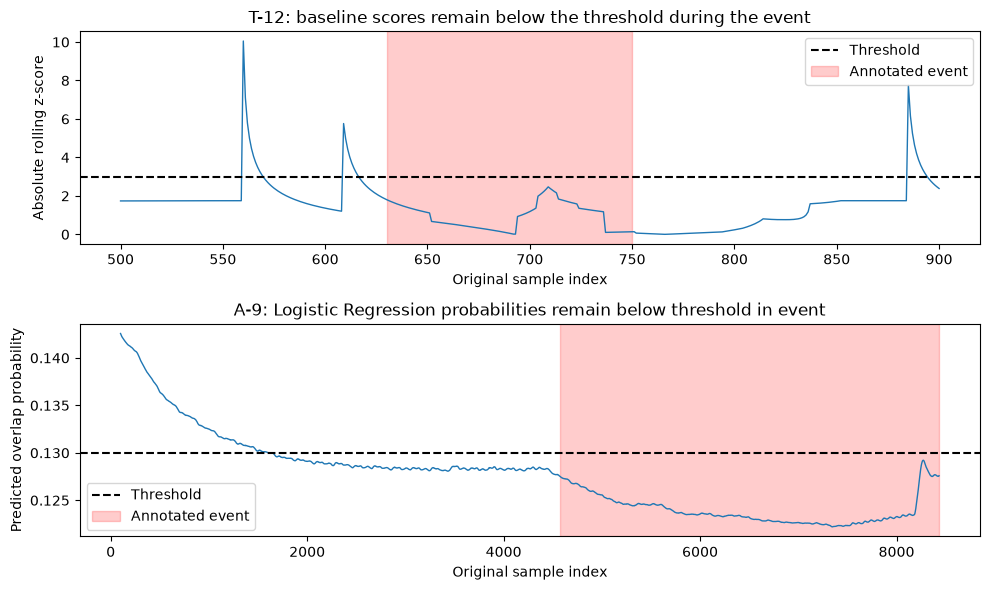

In [80]:
figure_dir = Path("../results/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# Baseline miss: T-12.
t12_signal = np.load(
    test_dir / "T-12.npy",
    allow_pickle=False,
)[:, 0]

t12_scores = rolling_3sigma(t12_signal, window_size=100)
t12_view = t12_scores.loc[500:900]

axes[0].plot(t12_view.index, t12_view["score"], linewidth=1)
axes[0].axhline(3.0, color="black", linestyle="--", label="Threshold")
axes[0].axvspan(
    630, 750, color="red", alpha=0.2, label="Annotated event"
)
axes[0].set(
    title="T-12: baseline scores remain below the threshold during the event",
    xlabel="Original sample index",
    ylabel="Absolute rolling z-score",
)
axes[0].legend()

# Logistic Regression miss: A-9.
a9_start = int(a9_event["start"])
a9_end = int(a9_event["end"])

axes[1].plot(
    a9_rows["sample_index"],
    a9_rows["score"],
    linewidth=1,
)
axes[1].axhline(0.13, color="black", linestyle="--", label="Threshold")
axes[1].axvspan(
    a9_start, a9_end, color="red", alpha=0.2,
    label="Annotated event",
)
axes[1].set(
    title="A-9: Logistic Regression probabilities remain below threshold in event",
    xlabel="Original sample index",
    ylabel="Predicted overlap probability",
)
axes[1].legend()

fig.tight_layout()
fig.savefig(
    figure_dir / "held_out_failure_examples.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

Held-out candidate-generation failures. Shading marks annotated events; dashed lines show frozen candidate thresholds. T-12’s maximum event score was 2.47, below 3σ. A-9’s maximum event probability was 0.12922, below 0.13. Neither event generated candidates, so alert ranking and suppression could not recover them.

In [81]:
from satmon.data import load_channel_splits

saved_splits = load_channel_splits("../splits/channels.json")

for name, channels in saved_splits.items():
    print(name, len(channels))

assert set(saved_splits["train"]) == set(train["chan_id"])
assert set(saved_splits["validation"]) == set(validation["chan_id"])
assert set(saved_splits["test"]) == set(test["chan_id"])

train 48
validation 16
test 16


In [82]:
from satmon.data import load_channel_signal

p1_row = train.loc[train["chan_id"] == "P-1"].iloc[0]

loaded_signal = load_channel_signal(
    test_dir,
    channel_id="P-1",
    expected_length=int(p1_row["num_values"]),
)

np.testing.assert_array_equal(
    loaded_signal,
    np.load(test_dir / "P-1.npy", allow_pickle=False)[:, 0],
)

print("Channel loader matches the original array.")

Channel loader matches the original array.


In [83]:
from satmon.features import assemble_split_examples as assemble_saved_split

rebuilt_training = assemble_saved_split(
    train,
    test_dir=test_dir,
    window_size=100,
    first_prediction_index=100,
)

pd.testing.assert_frame_equal(
    rebuilt_training,
    window_tables[100]["train"],
)

print("Backend assembly matches the notebook table.")

Backend assembly matches the notebook table.


In [84]:
rebuilt_test = assemble_saved_split(
    test,
    test_dir=test_dir,
    window_size=100,
    first_prediction_index=100,
)

pd.testing.assert_frame_equal(
    rebuilt_test,
    test_examples,
)

print("Backend assembly matches the test table.")

Backend assembly matches the test table.


In [85]:
training_order = train["chan_id"].tolist()

order_path = Path("../splits/training_channel_order.json")
order_path.write_text(
    json.dumps(training_order, indent=2) + "\n",
    encoding="utf-8",
)

print("Saved training order:", training_order[:5])

Saved training order: ['T-8', 'T-3', 'P-4', 'E-4', 'B-1']


In [86]:
original_summary = pd.read_csv(
    "../results/final_test/summary.csv",
    index_col="method",
).sort_index()

reproduced_summary = pd.read_csv(
    "../results/reproduction/summary.csv",
    index_col="method",
).sort_index()

pd.testing.assert_frame_equal(original_summary, reproduced_summary)

count_columns = [
    "n_events",
    "n_detected_events",
    "n_missed_events",
    "n_selected_alerts",
    "n_false_alerts",
]

original_channels = pd.read_csv(
    "../results/final_test/channels.csv"
).set_index(["method", "channel"]).sort_index()

reproduced_channels = pd.read_csv(
    "../results/reproduction/channels.csv"
).set_index(["method", "channel"]).sort_index()

pd.testing.assert_frame_equal(
    original_channels[count_columns],
    reproduced_channels[count_columns],
)

print("Summary and all per-channel counts match.")

Summary and all per-channel counts match.


In [87]:
final_logistic = window_models[(100, "logistic")]

final_coefficients = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": final_logistic.named_steps["model"].coef_[0],
})

display(final_coefficients)

print(
    "Intercept:",
    final_logistic.named_steps["model"].intercept_[0],
)

final_coefficients.to_csv(
    final_dir / "logistic_coefficients.csv",
    index=False,
)

,feature,coefficient
0,value,0.157185
1,delta,-0.008751
2,rolling_mean,0.119672
3,rolling_std,0.224760


Intercept: -1.8328372661979055


Logistic Regression provides explicit feature associations, with positive coefficients for rolling variability, current value, and rolling mean. However, its additive linear decision function may inadequately represent contextual patterns. This is a model limitation to investigate, not an established explanation for every miss.

In [88]:
final_training_features = window_tables[100]["train"][feature_columns]

feature_correlations = final_training_features.corr()
display(feature_correlations)

feature_correlations.to_csv(
    tuning_dir / "training_feature_correlations.csv",
)

,value,delta,rolling_mean,rolling_std
value,1.000000,0.099726,0.910381,0.659287
delta,0.099726,1.000000,0.000454,0.015969
rolling_mean,0.910381,0.000454,1.000000,0.415296
rolling_std,0.659287,0.015969,0.415296,1.000000


In [ ]:
final_forest = window_models[(100, "forest")]

forest_importances = pd.DataFrame({
    "feature": feature_columns,
    "importance": final_forest.feature_importances_,
}).sort_values("importance", ascending=False)

display(forest_importances)

forest_importances.to_csv(
    final_dir / "forest_feature_importances.csv",
    index=False,
)